# Домашнее задание 1. Рекомендация новых товаров
**Солодова Дарья Сергеевна**

Цель: сравнить пять собственных моделей персональных top-10 рекомендаций на **UCI Online Retail**.
Покупка трактуется как неявная положительная обратная связь. Рекомендуем товары, которых ещё нет
в истории пользователя на момент выдачи. Релевантен товар, купленный хотя бы один раз в следующем
временном окне, независимо от количества, цены и таргета конкретной модели.

Основная метрика **NDCG@10** выбрана **до подбора**: выше ценим попадания в начало короткой выдачи.
Recall@10 измеряет долю найденных будущих новых покупок. Precision@10 показывает долю полезных
позиций выдачи. Coverage@10 характеризует разнообразие по каталогу, но не заменяет качество.

### Воспроизведение эксперимента
Используется Python 3.12. Из корня проекта в отдельном окружении:

```bash
python -m pip install -r requirements.txt
python run_experiments.py
```

Данные автоматически загружаются из UCI при первом запуске; затем используется локальный кеш.
Скрипт выполняет ноутбук целиком и сохраняет результаты в нём. Seed = 42; настройки экспериментов
зафиксированы ниже. Создание окружения и варианты запуска описаны в [README](README.md).

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
import json, random, platform, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_utils import load_data, clean_data, make_protocol, make_features, TRAIN_END, VALID_END
from evaluation import evaluate, recommend, paired_bootstrap
from experiment_utils import SEARCH, tune
from models.fm import FM
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=1)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_colwidth', 180)
Path('results').mkdir(exist_ok=True)
started = time.perf_counter()
print('Python:', platform.python_version(), '| NumPy:', np.__version__, '| seed:', SEED)


Matplotlib is building the font cache; this may take a moment.


Python: 3.12.14 | NumPy: 2.2.6 | seed: 42


## 1. Источник и поля
[Первоисточник UCI](https://archive.ics.uci.edu/dataset/352/online+retail),
[DOI: 10.24432/C5BW33](https://doi.org/10.24432/C5BW33), Daqing Chen (2015), лицензия CC BY 4.0.
[Прямой архив](https://archive.ics.uci.edu/static/public/352/online+retail.zip).
Это продажи британского интернет-магазина подарков за 2010–2011 годы; среди покупателей есть оптовики.
Выборка используется целиком после очистки, случайная подвыборка не нужна.

| Поле | Смысл и использование |
|---|---|
| CustomerID | Идентификатор покупателя |
| StockCode | Идентификатор товара |
| InvoiceNo | Номер чека, префикс C означает отмену |
| InvoiceDate | Время покупки; временной split |
| Quantity | Количество единиц; очистка и EDA, не оценка предпочтения |
| UnitPrice | Цена единицы в GBP; исторические ценовые группы для FM |
| Description | Название товара; токены для FM |
| Country | Страна покупателя; метапризнак FM |

Данные загружаются из архива UCI функцией `load_data`. Затем читается файл `Online Retail.xlsx`.
Контрольная сумма архива проверяется по `dataset_manifest.json`, чтобы зафиксировать версию данных.
Одна строка — товарная позиция в чеке: несколько строк одного пользователя могут относиться к одной покупке.
Поэтому число строк, число событий «пользователь — товар — чек» и число уникальных user-item пар различаются.

In [2]:
raw, sha256 = load_data()
print('Исходный объём:', raw.shape)
display(raw.head())
display(pd.DataFrame({'Тип': raw.dtypes.astype(str),
                      'Уникальных значений': raw.nunique(),
                      'Пропусков': raw.isna().sum(),
                      'Пропуски, %': 100 * raw.isna().mean()}))
print('Период:', raw.InvoiceDate.min(), '—', raw.InvoiceDate.max())

Исходный объём: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,Тип,Уникальных значений,Пропусков,"Пропуски, %"
InvoiceNo,object,25900,0,0.000000
StockCode,object,4070,0,0.000000
Description,object,4223,1454,0.268311
Quantity,int64,722,0,0.000000
InvoiceDate,datetime64[ns],23260,0,0.000000
UnitPrice,float64,1630,0,0.000000
CustomerID,float64,4372,135080,24.926694
Country,object,38,0,0.000000


Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


## 2. EDA и подготовка данных
### 2.1. Пропуски, дубликаты и служебные операции
Сначала проверим, какие строки описывают покупку идентифицированного пользователя.
Пропуск CustomerID нельзя заполнить общим ID: так покупки разных людей превратятся в историю одного
несуществующего пользователя. Строки без ID или времени исключаем. Пустое название, напротив,
не мешает коллаборативной модели: для FM такой товар просто не имеет текстовых признаков.

Префикс C в номере чека указывает на отмену. Неположительные Quantity и UnitPrice также не считаем
положительной покупкой. Ниже причины проверяются независимо и могут пересекаться; это диагностика,
а точное число удалений будет в последовательной таблице очистки.

In [3]:
diagnostics = pd.DataFrame({
    'Причина': ['Нет CustomerID', 'Нет StockCode', 'Нет времени', 'Нет названия',
                'Точный дубликат', 'Отмена: InvoiceNo начинается с C', 'Quantity ≤ 0', 'UnitPrice ≤ 0',
                'Нетоварный формат StockCode'],
    'Строк': [raw.CustomerID.isna().sum(), raw.StockCode.isna().sum(), raw.InvoiceDate.isna().sum(),
              raw.Description.isna().sum(), raw.duplicated().sum(),
              raw.InvoiceNo.str.upper().str.startswith('C', na=False).sum(),
              (raw.Quantity <= 0).sum(), (raw.UnitPrice <= 0).sum(),
              (~raw.StockCode.str.fullmatch(r'\d{5}[A-Za-z]*', na=False)).sum()]
})
diagnostics['Доля исходных строк, %'] = 100 * diagnostics['Строк'] / len(raw)
display(diagnostics)
display(raw.loc[raw.duplicated(keep=False),
                ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'CustomerID']].head(8))
non_goods = raw.loc[~raw.StockCode.str.fullmatch(r'\d{5}[A-Za-z]*', na=False)]
display(non_goods.groupby('StockCode', dropna=False).agg(
    rows=('InvoiceNo', 'size'), example=('Description', 'first')).sort_values('rows', ascending=False).head(12))
display(Markdown(f"Без CustomerID находятся **{raw.CustomerID.isna().sum():,} строк "
                 f"({raw.CustomerID.isna().mean():.1%})**. Их удаление заметно сокращает данные и означает, "
                 "что выводы относятся к идентифицированным покупателям. "
                 f"Точных дубликатов **{raw.duplicated().sum():,}**; повторные покупки в разных чеках "
                 "дубликатами не считаются."))

,Причина,Строк,"Доля исходных строк, %"
0,Нет CustomerID,135080,24.926694
1,Нет StockCode,0,0.000000
2,Нет времени,0,0.000000
3,Нет названия,1454,0.268311
4,Точный дубликат,5268,0.972119
5,Отмена: InvoiceNo начинается с C,9288,1.713941
6,Quantity ≤ 0,10624,1.960477
7,UnitPrice ≤ 0,2517,0.464469
8,Нетоварный формат StockCode,2995,0.552676


,InvoiceNo,StockCode,Description,Quantity,CustomerID
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,17908.0
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,17908.0
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,17908.0
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,17908.0
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,17908.0
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,17908.0
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,17908.0
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,17908.0


,rows,example
StockCode,,
POST,1256,POSTAGE
DOT,710,DOTCOM POSTAGE
M,571,Manual
C2,144,CARRIAGE
D,77,Discount
S,63,SAMPLES
BANK CHARGES,37,Bank Charges
AMAZONFEE,34,AMAZON FEE
CRUK,16,CRUK Commission


Без CustomerID находятся **135,080 строк (24.9%)**. Их удаление заметно сокращает данные и означает, что выводы относятся к идентифицированным покупателям. Точных дубликатов **5,268**; повторные покупки в разных чеках дубликатами не считаются.

### 2.2. Последовательная очистка и итоговая выборка
Применяем правила в фиксированном порядке: обязательные поля → точные дубликаты → положительные
покупки → товарные коды. Для StockCode используем пять цифр с необязательным буквенным суффиксом.
Так исключаются почтовые сборы, скидки и бухгалтерские корректировки из примеров выше.
Это эвристика: без справочника каталога нельзя гарантировать, что каждый исключённый код служебный.

Удаление точных дубликатов также является допущением: одинаковая строка теоретически может быть
намеренно повторена в чеке. Для наших сигналов это менее критично, поскольку частота покупки
считается по различным чекам, а не по строкам. Отмены не связываем с исходной продажей;
положительная покупка впоследствии могла быть возвращена.

In [4]:
stages = [('Исходные данные', raw)]
stage = raw.dropna(subset=['CustomerID', 'StockCode', 'InvoiceDate'])
stages.append(('Заполнены обязательные поля', stage))
stage = stage.drop_duplicates()
stages.append(('Удалены точные дубликаты', stage))
stage = stage[(stage.Quantity > 0) & (stage.UnitPrice > 0)
              & ~stage.InvoiceNo.str.upper().str.startswith('C')]
stages.append(('Только положительные покупки', stage))
stage = stage[stage.StockCode.str.fullmatch(r'\d{5}[A-Za-z]*')]
stages.append(('Только товарные коды', stage))
cleaning_detail = pd.DataFrame([
    {'Шаг': name, 'Строк': len(frame), 'Пользователей': frame.CustomerID.nunique(),
     'Товаров': frame.StockCode.nunique()} for name, frame in stages])
cleaning_detail['Удалено на шаге'] = -cleaning_detail['Строк'].diff().fillna(0).astype(int)
cleaning_detail['Сохранено исходных строк, %'] = 100 * cleaning_detail['Строк'] / len(raw)
display(cleaning_detail)
clean, cleaning = clean_data(raw)
assert len(clean) == len(stage)
n_users, n_items = clean.CustomerID.nunique(), clean.StockCode.nunique()
n_events = len(clean[['CustomerID', 'StockCode', 'InvoiceNo']].drop_duplicates())
n_pairs = len(clean[['CustomerID', 'StockCode']].drop_duplicates())
assert 100_000 <= n_events <= 2_000_000 and n_users >= 1000 and n_items >= 1000
display(pd.DataFrame([{'Строк покупок': len(clean), 'Событий user-item-invoice': n_events,
    'Уникальных user-item пар': n_pairs, 'Пользователей': n_users, 'Товаров': n_items,
    'Разреженность': 1 - n_pairs / (n_users * n_items)}]))
display(Markdown(f"После очистки осталось **{len(clean):,} строк**, **{n_events:,} событий**, "
                 f"**{n_users:,} пользователей** и **{n_items:,} товаров**. "
                 "Требования к объёму выполнены и после агрегации строк в события. "
                 "Используем всю очищенную выборку: дополнительная подвыборка не нужна. "
                 "Разреженность рассчитана по уникальным user-item парам, чтобы повторные покупки "
                 "не завышали заполненность матрицы."))

,Шаг,Строк,Пользователей,Товаров,Удалено на шаге,"Сохранено исходных строк, %"
0,Исходные данные,541909,4372,4070,0,100.000000
1,Заполнены обязательные поля,406829,4372,3684,135080,75.073306
2,Удалены точные дубликаты,401604,4372,3684,5225,74.109122
3,Только положительные покупки,392692,4338,3665,8912,72.464565
4,Только товарные коды,391150,4334,3659,1542,72.180015


,Строк покупок,Событий user-item-invoice,Уникальных user-item пар,Пользователей,Товаров,Разреженность
0,391150,386326,266221,4334,3659,0.983212


После очистки осталось **391,150 строк**, **386,326 событий**, **4,334 пользователей** и **3,659 товаров**. Требования к объёму выполнены и после агрегации строк в события. Используем всю очищенную выборку: дополнительная подвыборка не нужна. Разреженность рассчитана по уникальным user-item парам, чтобы повторные покупки не завышали заполненность матрицы.

### 2.3. Активность пользователей и популярность товаров
Для решений о признаках и фильтрации далее используем только данные до **1 сентября 2011 года**,
то есть будущий train. Это не позволяет популярности товаров из validation/test влиять на подготовку.
Полное временное разбиение описано в разделе 3.

Активность измерим числом разных товаров и числом чеков. Популярность товара — числом уникальных
покупателей. Большая покупка одного оптовика при таком определении не делает товар популярным.
Логарифмические шкалы помогают увидеть редкие и очень активные объекты на одном графике.

,unique_items,invoices,events
count,3314.00,3314.00,3314.00
mean,49.01,3.42,66.71
std,66.12,5.54,137.72
min,1.00,1.00,1.00
10%,6.00,1.00,6.00
25%,13.00,1.00,14.00
50%,29.00,2.00,32.00
75%,62.00,4.00,75.00
90%,110.00,7.00,150.00
95%,162.00,10.00,228.70


,unique_users,events
count,3388.00,3388.00
mean,47.94,65.25
std,64.54,103.60
min,1.00,1.00
10%,2.00,2.00
25%,7.00,8.00
50%,24.00,27.00
75%,63.25,79.00
90%,127.00,174.00
95%,172.00,248.00


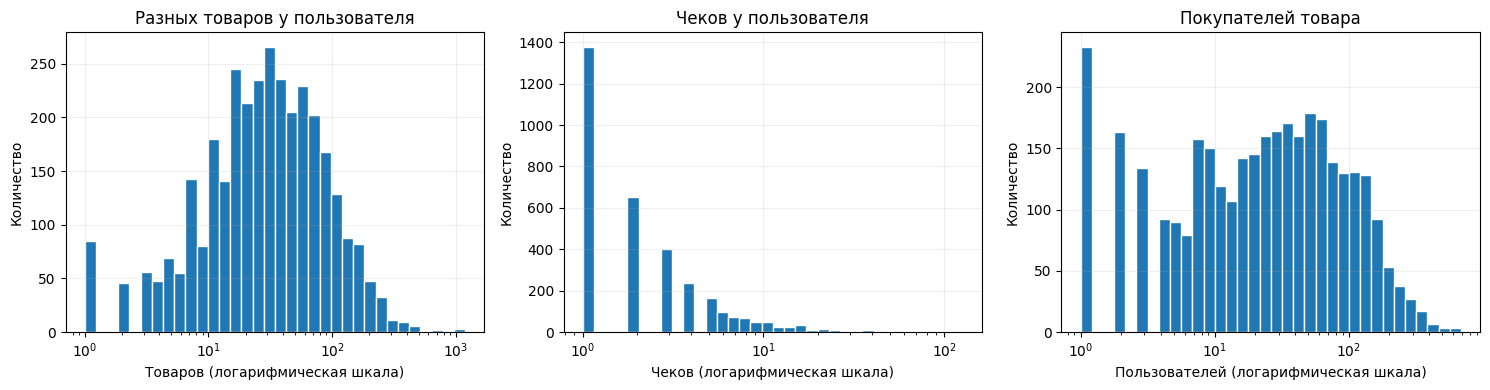

Медианный пользователь покупал **29 разных товаров** в **2 чеках**; 99-й перцентиль числа товаров — **272**. У медианного товара **24 покупателей**, у самого популярного — **686**. Средние и верхние квантили нужно рассматривать отдельно: немногочисленные активные покупатели и популярные товары не описывают типичную историю.

In [5]:
eda_train = clean[clean.InvoiceDate < TRAIN_END].copy()
train_events = eda_train[['CustomerID', 'StockCode', 'InvoiceNo']].drop_duplicates()
user_stats = train_events.groupby('CustomerID').agg(
    unique_items=('StockCode', 'nunique'), invoices=('InvoiceNo', 'nunique'), events=('StockCode', 'size'))
item_stats = train_events.groupby('StockCode').agg(
    unique_users=('CustomerID', 'nunique'), events=('CustomerID', 'size'))
display(user_stats.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(2))
display(item_stats.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, values, title, xlabel in [
    (axes[0], user_stats.unique_items, 'Разных товаров у пользователя', 'Товаров'),
    (axes[1], user_stats.invoices, 'Чеков у пользователя', 'Чеков'),
    (axes[2], item_stats.unique_users, 'Покупателей товара', 'Пользователей')]:
    ax.hist(values, bins=np.geomspace(1, values.max()+1, 35), edgecolor='white')
    ax.set_xscale('log')
    ax.set(title=title, xlabel=xlabel + ' (логарифмическая шкала)', ylabel='Количество')
plt.tight_layout(); plt.show()
display(Markdown(f"Медианный пользователь покупал **{user_stats.unique_items.median():.0f} разных товаров** "
    f"в **{user_stats.invoices.median():.0f} чеках**; 99-й перцентиль числа товаров — "
    f"**{user_stats.unique_items.quantile(.99):.0f}**. У медианного товара "
    f"**{item_stats.unique_users.median():.0f} покупателей**, у самого популярного — "
    f"**{item_stats.unique_users.max():,}**. Средние и верхние квантили нужно рассматривать отдельно: "
    "немногочисленные активные покупатели и популярные товары не описывают типичную историю."))

### 2.4. Концентрация спроса и редкие истории
Проверим, какую долю взаимодействий дают самые популярные товары, и сколько данных потеряется
при минимальном пороге активности. В таблице пороги для пользователей и товаров применяются
**независимо**, по числу уникальных соседей в train. Это анализ чувствительности, не совместный k-core.

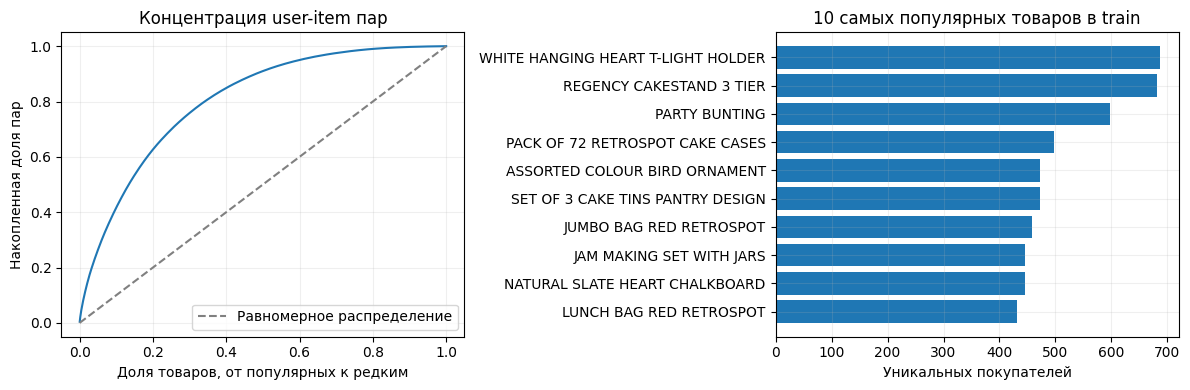

,Фильтр,Минимум уникальных соседей,Удалено сущностей,"Сохранено сущностей, %","Сохранено событий, %"
0,Пользователи,2,85,97.435124,99.950695
1,Товары,2,233,93.122786,99.881488
2,Пользователи,5,235,92.908871,99.716386
3,Товары,5,622,81.641086,99.352256
4,Пользователи,10,582,82.438141,98.447133
5,Товары,10,1037,69.391972,97.880357


На верхние 10% товаров приходится **41.7% уникальных user-item пар**. Поэтому наряду с точностью оцениваем Coverage@10. Порог ≥5 разных товаров исключил бы **235 пользователей**, а порог ≥5 покупателей — **622 товаров**. В основном эксперименте эти пороги не применяем: сохраняем редкие истории и товары, чтобы не оценивать модели только на более лёгком популярном подмножестве. Цена такого выбора — менее надёжные оценки сходства и факторов для редких объектов.

In [6]:
popularity = item_stats.unique_users.sort_values(ascending=False)
concentration = popularity.cumsum() / popularity.sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, len(popularity)+1) / len(popularity), concentration)
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Равномерное распределение')
axes[0].set(title='Концентрация user-item пар', xlabel='Доля товаров, от популярных к редким',
            ylabel='Накопленная доля пар'); axes[0].legend()
names = eda_train.groupby('StockCode').Description.last()
top = popularity.head(10).sort_values()
axes[1].barh([str(names.loc[i])[:34] for i in top.index], top.values)
axes[1].set(title='10 самых популярных товаров в train', xlabel='Уникальных покупателей')
plt.tight_layout(); plt.show()
sensitivity = []
for threshold in [2, 5, 10]:
    kept_users = user_stats.index[user_stats.unique_items >= threshold]
    kept_items = item_stats.index[item_stats.unique_users >= threshold]
    for entity, kept, column, total in [('Пользователи', kept_users, 'CustomerID', len(user_stats)),
                                       ('Товары', kept_items, 'StockCode', len(item_stats))]:
        sensitivity.append({'Фильтр': entity, 'Минимум уникальных соседей': threshold,
            'Удалено сущностей': total-len(kept), 'Сохранено сущностей, %': 100*len(kept)/total,
            'Сохранено событий, %': 100*train_events[column].isin(kept).mean()})
display(pd.DataFrame(sensitivity))
top_count = int(np.ceil(.1 * len(popularity)))
display(Markdown(f"На верхние 10% товаров приходится **{concentration.iloc[top_count-1]:.1%} "
    "уникальных user-item пар**. Поэтому наряду с точностью оцениваем Coverage@10. "
    f"Порог ≥5 разных товаров исключил бы **{(user_stats.unique_items < 5).sum():,} пользователей**, "
    f"а порог ≥5 покупателей — **{(item_stats.unique_users < 5).sum():,} товаров**. "
    "В основном эксперименте эти пороги не применяем: сохраняем редкие истории и товары, "
    "чтобы не оценивать модели только на более лёгком популярном подмножестве. "
    "Цена такого выбора — менее надёжные оценки сходства и факторов для редких объектов."))

### 2.5. Повторные покупки и величина сигнала
Число единиц в чеке и число повторных посещений — разные сигналы. Покупка 100 единиц за один раз
не обязательно означает более сильное предпочтение, чем несколько отдельных покупок.
Поэтому для iALS используем число **различных чеков** с товаром. Посмотрим, достаточно ли
повторений, чтобы эксперимент с кастомным таргетом отличался от бинарного случая.

,Событий на пару,Товаров в чеке
count,162426.00,11342.00
mean,1.36,19.49
std,1.05,19.74
min,1.00,1.00
50%,1.00,14.00
90%,2.00,43.00
99%,6.00,92.00
max,43.00,271.00


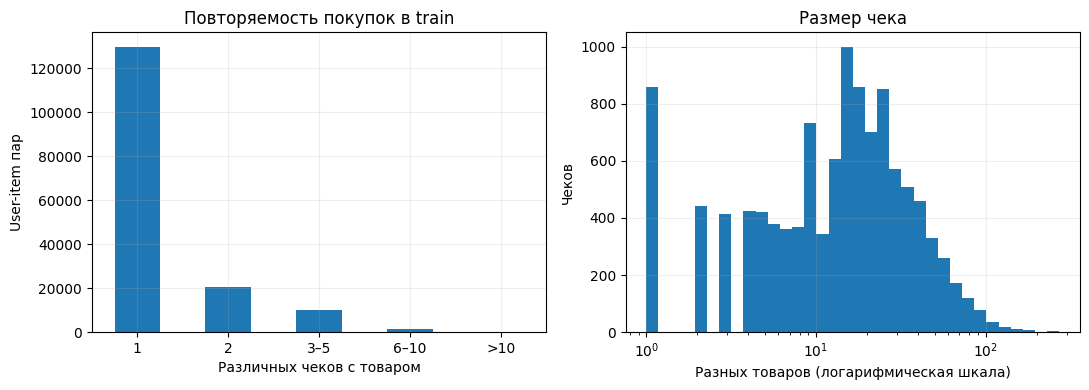

Повторные покупки есть у **20.1% user-item пар**; они дают **41.3% событий**. У **50.9% пользователей** частота различается между товарами — именно для них нормированный кастомный таргет меняет относительную силу наблюдённых интересов. Для остальных его значения совпадают с бинарным таргетом. Это обосновывает проверку сигнала повторяемости, но само по себе не доказывает его пользу для рекомендаций новых товаров.

In [7]:
repeat_counts = train_events.groupby(['CustomerID', 'StockCode']).size()
basket_sizes = train_events.groupby(['CustomerID', 'InvoiceNo']).StockCode.nunique()
display(pd.DataFrame({'Событий на пару': repeat_counts.describe(percentiles=[.5,.9,.99]),
                      'Товаров в чеке': basket_sizes.describe(percentiles=[.5,.9,.99])}).round(2))
repeat_groups = pd.cut(repeat_counts, bins=[0,1,2,5,10,np.inf], labels=['1','2','3–5','6–10','>10'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
repeat_groups.value_counts(sort=False).plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Повторяемость покупок в train', xlabel='Различных чеков с товаром', ylabel='User-item пар')
axes[1].hist(basket_sizes, bins=np.geomspace(1, basket_sizes.max()+1, 35))
axes[1].set_xscale('log')
axes[1].set(title='Размер чека', xlabel='Разных товаров (логарифмическая шкала)', ylabel='Чеков')
plt.tight_layout(); plt.show()
unequal = repeat_counts.groupby(level=0).nunique().gt(1)
display(Markdown(f"Повторные покупки есть у **{(repeat_counts > 1).mean():.1%} user-item пар**; "
    f"они дают **{repeat_counts[repeat_counts > 1].sum()/repeat_counts.sum():.1%} событий**. "
    f"У **{unequal.mean():.1%} пользователей** частота различается между товарами — "
    "именно для них нормированный кастомный таргет меняет относительную силу наблюдённых интересов. "
    "Для остальных его значения совпадают с бинарным таргетом. "
    "Это обосновывает проверку сигнала повторяемости, но само по себе не доказывает его пользу для рекомендаций новых товаров."))

### 2.6. Цена, количество и выбросы
Проверим хвосты Quantity и UnitPrice на train. Большие значения могут быть связаны с оптовыми
покупками, а не с ошибкой. Без дополнительных сведений не удаляем положительные покупки только
за большой размер. Quantity не входит напрямую в таргет, поэтому одна крупная партия не получает
пропорционально больший вес. Для FM используем группу медианной исторической цены товара,
а не цену конкретной будущей покупки.

,Quantity,UnitPrice
count,223127.000,223127.000
mean,13.720,2.973
std,163.632,4.940
min,1.000,0.040
50%,6.000,1.950
90%,24.000,6.750
95%,48.000,8.500
99%,144.000,12.750
99.9%,576.000,39.950
max,74215.000,649.500


,StockCode,Description,Quantity,UnitPrice,InvoiceDate
36375,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00
140979,22197,SMALL POPCORN HOLDER,4300,0.72,2011-05-27 10:52:00
60437,22053,EMPIRE DESIGN ROSETTE,3906,0.82,2011-02-22 10:43:00
185900,18007,ESSENTIAL BALM 3.5G TIN IN ENVELOPE,3186,0.06,2011-07-19 17:04:00
32069,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-01-11 12:55:00


,StockCode,Description,Quantity,UnitPrice,InvoiceDate
152957,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5,2011-06-10 15:28:00
152958,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,2011-06-10 15:33:00
3628,22655,VINTAGE RED KITCHEN CABINET,1,295.0,2010-12-02 18:06:00
21014,22655,VINTAGE RED KITCHEN CABINET,1,295.0,2010-12-16 08:41:00
31292,22655,VINTAGE RED KITCHEN CABINET,1,295.0,2011-01-10 14:57:00


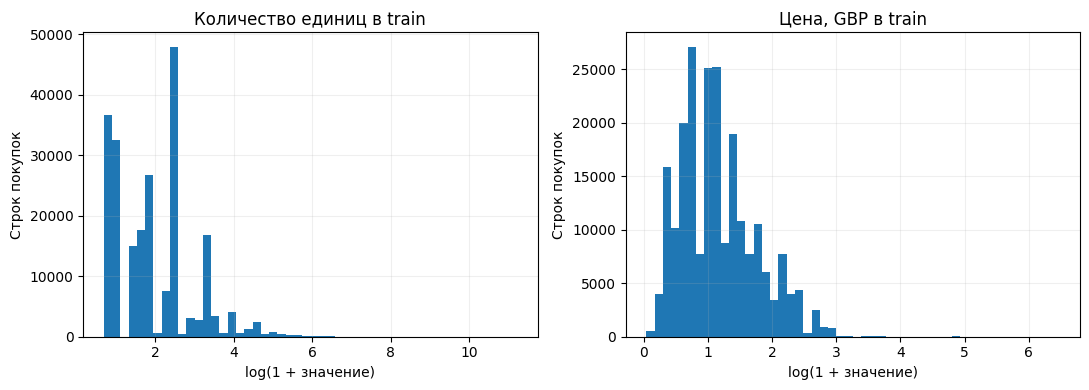

Для Quantity медиана равна **6**, 99-й перцентиль — **144**, максимум — **74215**. Для UnitPrice соответствующие значения: **1.95**, **12.75**, **649.50 GBP**. Разрыв между типичными и максимальными значениями поддерживает выбор устойчивых агрегатов и логарифмического confidence вместо линейного веса по количеству единиц.

In [8]:
display(eda_train[['Quantity', 'UnitPrice']].describe(percentiles=[.5,.9,.95,.99,.999]).round(3))
display(eda_train.nlargest(5, 'Quantity')[['StockCode','Description','Quantity','UnitPrice','InvoiceDate']])
display(eda_train.nlargest(5, 'UnitPrice')[['StockCode','Description','Quantity','UnitPrice','InvoiceDate']])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, label in [(axes[0], 'Quantity', 'Количество единиц'), (axes[1], 'UnitPrice', 'Цена, GBP')]:
    ax.hist(np.log1p(eda_train[column]), bins=50)
    ax.set(title=label + ' в train', xlabel='log(1 + значение)', ylabel='Строк покупок')
plt.tight_layout(); plt.show()
display(Markdown(f"Для Quantity медиана равна **{eda_train.Quantity.median():g}**, "
    f"99-й перцентиль — **{eda_train.Quantity.quantile(.99):g}**, максимум — **{eda_train.Quantity.max():g}**. "
    f"Для UnitPrice соответствующие значения: **{eda_train.UnitPrice.median():.2f}**, "
    f"**{eda_train.UnitPrice.quantile(.99):.2f}**, **{eda_train.UnitPrice.max():.2f} GBP**. "
    "Разрыв между типичными и максимальными значениями поддерживает выбор устойчивых агрегатов "
    "и логарифмического confidence вместо линейного веса по количеству единиц."))

### 2.7. Метаданные для FM
В данных нет готовой товарной категории. Вместо неё используем слова названия: они описывают тип,
цвет и оформление товара. Проверим заполненность названий, смену описания у одного StockCode,
ценовую вариативность и распределение стран. Все приведённые ниже значения относятся к train.
Для модели берём последнее известное название и страну, медианную цену; словарь ограничиваем
128 наиболее распространёнными словами, чтобы не вводить множество редко наблюдаемых признаков.

Пустых последних названий                   0.000000
Товаров с несколькими названиями          140.000000
Товаров с несколькими ценами             2022.000000
Пользователей с несколькими странами        6.000000
Уникальных слов в названиях              1813.000000
Покрытие товаров словарём из 128 слов       0.928867
Name: Значение, dtype: float64

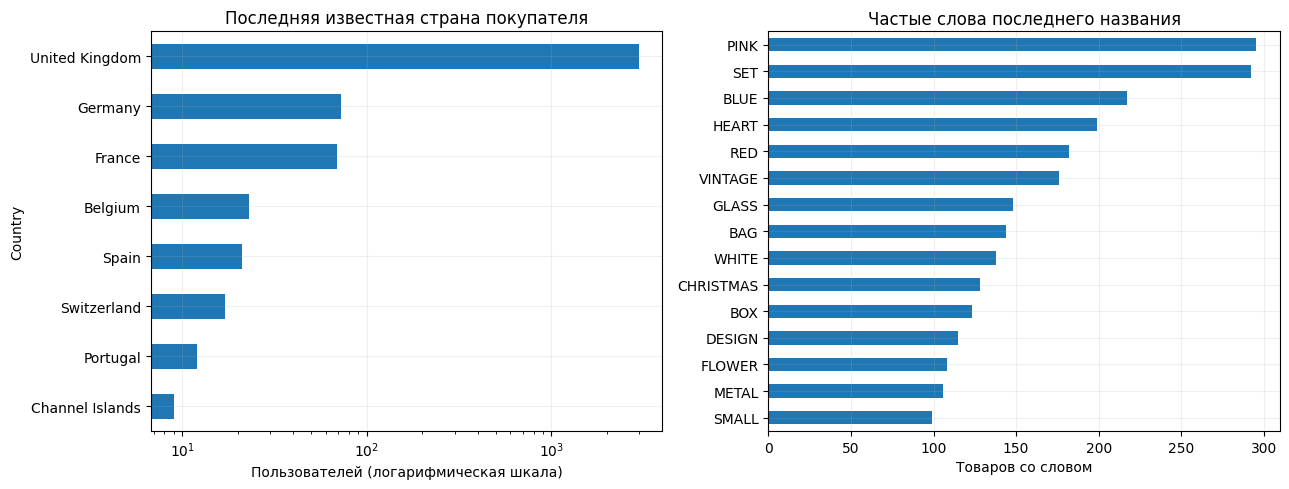

**90.1% пользователей** имеют страну United Kingdom; такой дисбаланс ограничивает информативность страны. Словарь покрывает хотя бы одним словом **92.9% товаров**. У **140 товаров** название менялось, поэтому нельзя брать описание из конца всего датасета: это могло бы использовать будущие сведения. Для товаров без выбранных слов сохраняются ID и ценовая группа. Покрытие признаками ещё не означает прирост качества — его проверим сравнением FM с метаданными и без них.

In [9]:
import re
from collections import Counter
titles = eda_train.groupby('StockCode').Description.last()
title_variants = eda_train.groupby('StockCode').Description.nunique()
price_variants = eda_train.groupby('StockCode').UnitPrice.nunique()
country_variants = eda_train.groupby('CustomerID').Country.nunique()
last_countries = eda_train.groupby('CustomerID').Country.last()
token_sets = titles.map(lambda title: set(re.findall(r'[A-Z]{3,}', title)))
token_frequency = Counter(token for tokens in token_sets for token in tokens)
vocabulary = sorted(token_frequency, key=lambda token: (-token_frequency[token], token))[:128]
vocab_set = set(vocabulary)
title_coverage = token_sets.map(lambda tokens: bool(tokens & vocab_set)).mean()
display(pd.Series({
    'Пустых последних названий': int(titles.eq('').sum()),
    'Товаров с несколькими названиями': int(title_variants.gt(1).sum()),
    'Товаров с несколькими ценами': int(price_variants.gt(1).sum()),
    'Пользователей с несколькими странами': int(country_variants.gt(1).sum()),
    'Уникальных слов в названиях': len(token_frequency),
    'Покрытие товаров словарём из 128 слов': title_coverage
}, name='Значение'))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
last_countries.value_counts().head(8).sort_values().plot.barh(ax=axes[0], logx=True)
axes[0].set(title='Последняя известная страна покупателя', xlabel='Пользователей (логарифмическая шкала)')
pd.Series(dict(token_frequency.most_common(15))).sort_values().plot.barh(ax=axes[1])
axes[1].set(title='Частые слова последнего названия', xlabel='Товаров со словом')
plt.tight_layout(); plt.show()
display(Markdown(f"**{last_countries.eq('United Kingdom').mean():.1%} пользователей** имеют страну "
    f"United Kingdom; такой дисбаланс ограничивает информативность страны. "
    f"Словарь покрывает хотя бы одним словом **{title_coverage:.1%} товаров**. "
    f"У **{title_variants.gt(1).sum()} товаров** название менялось, поэтому нельзя брать описание "
    "из конца всего датасета: это могло бы использовать будущие сведения. "
    "Для товаров без выбранных слов сохраняются ID и ценовая группа. "
    "Покрытие признаками ещё не означает прирост качества — его проверим сравнением FM с метаданными и без них."))

### 2.8. Временная структура
Покажем полный календарный диапазон, чтобы описать периоды оценки. Это описательная статистика:
по значениям будущих месяцев не меняем фильтры, признаки или настройки моделей.
Декабрь 2011 года неполный, поэтому сравнение месячных сумм без учёта числа дней некорректно.
Число строк покупок в среднем за наблюдаемый календарный день позволяет увидеть этот эффект отдельно.

,rows,users,items,observed_days,rows_per_calendar_day
InvoiceDate,,,,,
2010-12,25569,884,2407,31,824.8
2011-01,20896,739,2117,31,674.1
2011-02,19630,757,2121,28,701.1
2011-03,26750,973,2231,31,862.9
2011-04,22345,853,2212,30,744.8
2011-05,27960,1054,2215,31,901.9
2011-06,26820,990,2336,30,894.0
2011-07,26474,946,2347,31,854.0
2011-08,26683,933,2352,31,860.7


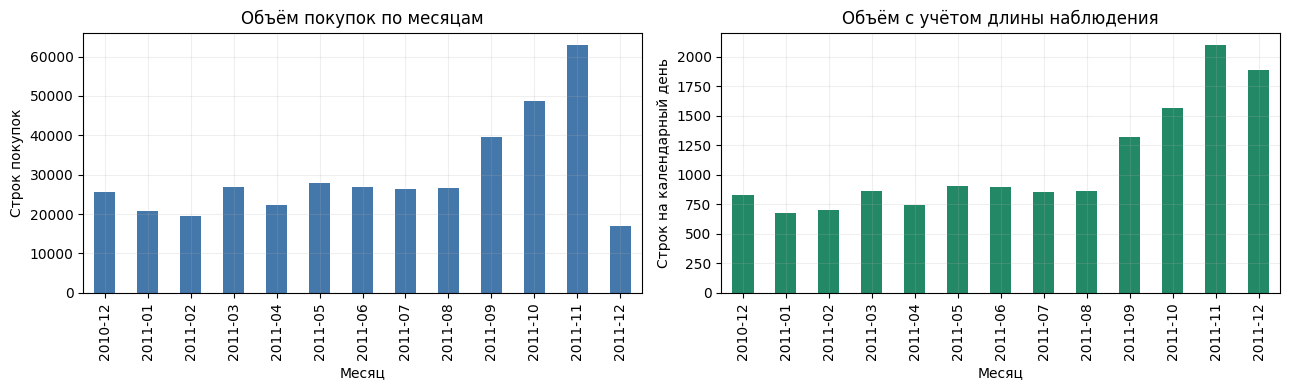

Последний месяц наблюдается только **9 дней**. Изменение месячного объёма может сочетать сезонность и изменения состава покупателей; одного года данных недостаточно, чтобы разделить эти причины. Поэтому используем временную, а не случайную оценку и не интерпретируем test как качество на любом времени года.

In [10]:
monthly = clean.groupby(clean.InvoiceDate.dt.to_period('M')).agg(
    rows=('InvoiceNo','size'), users=('CustomerID','nunique'), items=('StockCode','nunique'))
first_day, last_day = clean.InvoiceDate.min().normalize(), clean.InvoiceDate.max().normalize()
monthly['observed_days'] = [
    (min(period.end_time.normalize(), last_day) - max(period.start_time, first_day)).days+1
    for period in monthly.index]
monthly['rows_per_calendar_day'] = monthly.rows / monthly.observed_days
display(monthly.round(1))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly.rows.plot.bar(ax=axes[0], color='#4477aa')
monthly.rows_per_calendar_day.plot.bar(ax=axes[1], color='#228866')
for ax, title, ylabel in [(axes[0], 'Объём покупок по месяцам', 'Строк покупок'),
                         (axes[1], 'Объём с учётом длины наблюдения', 'Строк на календарный день')]:
    ax.set(title=title, xlabel='Месяц', ylabel=ylabel)
plt.tight_layout(); plt.show()
display(Markdown(f"Последний месяц наблюдается только **{monthly.observed_days.iloc[-1]} дней**. "
    "Изменение месячного объёма может сочетать сезонность и изменения состава покупателей; "
    "одного года данных недостаточно, чтобы разделить эти причины. Поэтому используем "
    "временную, а не случайную оценку и не интерпретируем test как качество на любом времени года."))

### Итоги подготовки
Сохраняем положительные покупки идентифицированных пользователей и товарные позиции чеков.
Повторы между чеками сохраняются как отдельный обучающий сигнал. Матрица бинарных предпочтений
строится по уникальным user-item парам; число чеков используется в confidence и в кастомном таргете.
Не вводим минимальный порог популярности и не удаляем положительные выбросы количества:
вместо этого ограничиваем их влияние выбором сигнала. Все преобразования метаданных обучаются
на train. Разреженность и концентрация спроса мотивируют сравнение соседских и факторных моделей,
а полезность метаданных и повторяемости будет проверена экспериментально.

## 3. Единый временной протокол
- **Train:** время < 2011-09-01. **Validation:** [2011-09-01, 2011-11-01).
  **Test:** [2011-11-01, конец данных]. Границы выбраны календарно, не по метрикам.
- Каталог и известные пользователи фиксируются **только по train**. Для каждой модели используется
  весь этот каталог, без семплирования кандидатов на оценке. Новые пользователи/товары исключены;
  ниже показаны потери покрытия. Оценивается warm-start сценарий.
- На validation исключаем товары из train. На test исключаем товары из train **и validation**,
  поскольку к 1 ноября они уже известны. Test-релевантность тоже исключает эти товары.
  Все выдачи статичны в начале окна, история внутри окна не обновляется.
- Пользователи оценки имеют хотя бы один релевантный новый товар и >=10 доступных кандидатов.
  Набор пользователей внутри каждого split одинаков у всех методов. Между validation и test
  когорты могут отличаться. Это условная оценка активных покупателей с новой покупкой, не всего трафика.
- Подбор только на validation NDCG@10. Затем настройки фиксируются. **Без дообучения на validation:**
  все модели остаются на одинаковом train. История validation используется только в маске известных
  товаров test. Так оценивается качество модели, обученной один раз до начала validation.
- Одинаковые баллы разрешаются сортировкой StockCode по возрастанию. NDCG, Recall и Precision усредняются по пользователям; Coverage рассчитывается по всей выдаче когорты.

Пусть $U$ — множество оцениваемых пользователей, $G_u$ — множество релевантных товаров пользователя,
$L_u$ — его выдача из 10 товаров, а $L_{ur}$ — товар на позиции $r$. Индикатор $\mathbf{1}[A]$
равен 1, если условие $A$ выполнено, и 0 иначе. Тогда:

$$
\operatorname{Recall}@10 = \frac{1}{|U|}\sum_u\frac{|L_u\cap G_u|}{|G_u|}
$$

$$
\operatorname{NDCG}@10 = \frac{1}{|U|}\sum_u\frac{\sum_{r=1}^{10}\mathbf{1}[L_{ur}\in G_u]/\log_2(r+1)}{\sum_{r=1}^{\min(10,|G_u|)}1/\log_2(r+1)}
$$

Precision@10 для пользователя — число попаданий, делённое на 10; итоговая метрика — среднее по пользователям.
Coverage@10 — число уникальных товаров во всех выдачах, делённое на размер train-каталога.
Больший Coverage означает более широкий охват каталога, но сам по себе не гарантирует релевантность.

In [11]:
protocol = make_protocol(clean)
counts = protocol['counts']
assert counts.shape[0] >= 1000 and counts.shape[1] >= 1000
assert protocol['train'].InvoiceDate.max() < TRAIN_END
assert counts.nnz >= 100_000
print('Train rows:', len(protocol['train']), '| shape:', counts.shape, '| unique pairs:', counts.nnz)
print('Train sparsity:', 1 - counts.nnz / np.prod(counts.shape))
display(protocol['audit'])
print('cold_user_rows и cold_item_rows могут пересекаться; их нельзя складывать.')
for phase in ['validation', 'test']:
    for u, target in protocol[phase].items():
        assert not np.intersect1d(target, protocol['seen_' + phase][u].indices).size

for row in protocol['audit'].itertuples():
    display(Markdown(f"В **{row.split}** после ограничения train-каталогом и известными пользователями "
        f"сохранено **{row.warm_rows / row.raw_rows:.1%} строк**. "
        f"Из **{row.warm_users:,}** известных активных покупателей в оценку вошли "
        f"**{row.evaluated_users:,}**: остальные не имеют подходящей новой покупки или достаточного числа кандидатов. "
        "Таким образом, метрики относятся к явно определённой warm-start когорте, а не ко всем покупкам окна."))


Train rows: 223127 | shape: (3314, 3388) | unique pairs: 162426
Train sparsity: 0.9855336275070735


,split,raw_rows,warm_rows,cold_user_rows,cold_item_rows,warm_users,evaluated_users,relevant_pairs
0,validation,88121,60899,22002,6785,1477,1407,33217
1,test,79902,52998,20655,8284,1333,1229,23586


cold_user_rows и cold_item_rows могут пересекаться; их нельзя складывать.


В **validation** после ограничения train-каталогом и известными пользователями сохранено **69.1% строк**. Из **1,477** известных активных покупателей в оценку вошли **1,407**: остальные не имеют подходящей новой покупки или достаточного числа кандидатов. Таким образом, метрики относятся к явно определённой warm-start когорте, а не ко всем покупкам окна.

В **test** после ограничения train-каталогом и известными пользователями сохранено **66.3% строк**. Из **1,333** известных активных покупателей в оценку вошли **1,229**: остальные не имеют подходящей новой покупки или достаточного числа кандидатов. Таким образом, метрики относятся к явно определённой warm-start когорте, а не ко всем покупкам окна.

## 4. Модели и формулы
Обозначения: $R_{ui}$ — число различных train-чеков с товаром, $B_{ui}=\mathbf{1}[R_{ui}>0]$.
Методы хранят обученное состояние и реализуют `score(users)`; общая `recommend` исключает известные товары.

**ItemKNN (`models/item_knn.py`).** Косинус по бинарным столбцам, shrinkage по совместной встречаемости:
$s_{ij}=\frac{B_i^TB_j}{\|B_i\|\|B_j\|}\frac{n_{ij}}{n_{ij}+\gamma}$, $s_{ii}=0$.
Здесь $n_{ij}=B_i^T B_j$ — число общих покупателей, $\gamma$ — параметр сглаживания.
Если общих покупателей нет, сходство полагаем равным нулю, включая случай $\gamma=0$.
В каждой строке оставляем k сильнейших соседей; остальные значения сходства обнуляем. Оценка $\hat r_{ui}=\sum_{j:B_{uj}=1}s_{ji}$.

**iALS (`models/ials.py`).**

$$
\min_{X,Y}\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2)
$$

$$
p_{ui}=B_{ui},\quad c_{ui}=1+\alpha\log(1+R_{ui})
$$

Здесь $x_u$ и $y_i$ — векторы факторов пользователя и товара; строки матриц $X$ и $Y$
содержат эти векторы. $\alpha$ управляет confidence, $\lambda$ — регуляризацией.
Для ненаблюдённых пар $p=0,c=1$. Обозначим через $I_u$ множество купленных товаров,
$Y_{I_u}$ — соответствующие строки матрицы факторов, $C_u$ — диагональную матрицу их confidence,
$p_u$ — вектор таргетов на этих товарах. Символ $I$ обозначает единичную матрицу нужного размера.
Попеременно решаем:

$$
x_u=(Y^TY+Y_{I_u}^T(C_u-I)Y_{I_u}+\lambda I)^{-1}Y_{I_u}^TC_up_u
$$

Для товаров аналогично. В коде используем `solve`, не явное обращение каждой матрицы.

**EASE (`models/ease.py`).** $\min_W\|B-BW\|_F^2+\lambda\|W\|_F^2$, $\operatorname{diag}W=0$.
$P=(B^TB+\lambda I)^{-1}$, $W_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$; scores $BW$.
Матрица $W$ связывает историю покупок с оценками товаров; нулевая диагональ исключает предсказание товара через него самого.

**FM (`models/fm.py`).**

$$
f(z)=w_0+\sum_jw_jz_j+\frac{1}{2}\sum_f[(\sum_jv_{jf}z_j)^2-\sum_jv_{jf}^2z_j^2]
$$

Здесь $z$ — разреженный вектор признаков пары пользователь–товар, $w_0$ — смещение,
$w_j$ — линейные веса, а $v_{jf}$ — параметры взаимодействий признаков.
Обучаем FM по логистической BCE на бинарных train-парах и трёх равномерных ненаблюдённых парах на положительную,
средняя BCE + $\lambda(\|w\|^2+\|V\|_F^2)/2$. Негативы обновляются каждую эпоху; train-покупки исключены,
будущие покупки неизвестны и могут стать ложными негативами. Градиенты и Adam реализованы вручную.
На оценке ранжируем логиты по полному каталогу, а не только по обучающим негативам.

Признаки: user ID, item ID, последняя train-страна покупателя, 128 частых слов названия товара
(multi-hot с L2-нормировкой), квантильная группа медианной train-цены.
Слова отражают тип/стиль товара; ценовая группа — исторический ценовой сегмент; страна — географию спроса.
Словарь, границы и значения вычисляются **только на train**, доступны к обеим выдачам и заморожены.
Названия/цены будущего окна и количество будущей покупки не используются.
Это признаки снимка каталога на дату выдачи, а не симуляция признаков на дату каждой train-транзакции.
Контрольная FM без метаданных обучается при тех же выбранных настройках для ablation.

**iALS с собственным таргетом (`models/custom_ials.py`).** Гипотеза: повторные покупки лучше отражают
устойчивые предпочтения, чем разовые; нормировка внутри пользователя уменьшает различия частоты визитов.

$$
p^*_{ui}=\begin{cases}(1-\beta)+\beta\frac{\log(1+R_{ui})}{\max_{j:R_{uj}>0}\log(1+R_{uj})},&R_{ui}>0,\\0,&R_{ui}=0.\end{cases}
$$

У пользователя с единственными покупками всех товаров таргет остаётся 1. При повторениях меньшие значения
получают относительно менее устойчивые интересы. Это интенсивность предпочтения, **не вероятность**.
Меняется именно $p$, а $c$, train, факторы, регуляризация, число итераций и seed совпадают с выбранным iALS.
Меняется правая часть ALS-уравнения; это не только изменение confidence. При $\beta=0$ получается базовый iALS.
При этом задача test остаётся прежней: новые покупки, без весов повторяемости. Гипотеза может не сработать,
поскольку повторяемость обучающих покупок не обязана помогать поиску новых товаров.

In [12]:
uf, itf, feature_info = make_features(protocol['train'], *counts.shape)
display(pd.DataFrame([
    {'Признаки': 'Пользователь: ID + страна', 'Строк': uf.shape[0], 'Столбцов': uf.shape[1]},
    {'Признаки': 'Товар: ID + слова + ценовая группа', 'Строк': itf.shape[0], 'Столбцов': itf.shape[1]}
]))
print('Границы ценовых групп в GBP:', np.round(np.expm1(feature_info['log_price_edges']), 2))


,Признаки,Строк,Столбцов
0,Пользователь: ID + страна,3314,3350
1,Товар: ID + слова + ценовая группа,3388,3521


Границы ценовых групп в GBP: [0.85 1.42 2.55 4.25]


### Подбор на validation
Небольшой полный перебор заранее заданных сеток ниже. Для iALS фиксированы alpha=20 и 12 итераций;
для FM — 10 эпох, learning rate 0.01, 3 негатива, batch size 2048. По 4 конфигурации KNN, iALS и FM,
3 EASE и 3 beta для custom iALS. Это ограниченный бюджет, а не гарантия глобального оптимума.
При равенстве основной метрики побеждает первая конфигурация в заданном порядке.
Beta=0 служит базовой контрольной точкой и не входит в поиск пятой модели.
Test-метрики рассчитываются в разделе 5 после фиксации настроек всех моделей.

In [13]:
display(pd.DataFrame([{'model': name, 'search': options} for name, options in SEARCH.items()]))
models, selected, logs = {}, {}, []
for name in ['ItemKNN', 'IALS', 'EASE', 'FM', 'RepeatTargetIALS']:
    model, params, log = tune(name, protocol, features=(uf, itf),
                              base_params=selected['IALS'] if name == 'RepeatTargetIALS' else None)
    models[name], selected[name] = model, params
    logs.append(log)
validation_results = pd.concat(logs, ignore_index=True)
display(validation_results.sort_values(['model', 'NDCG@10'], ascending=[True, False]))
validation_results.to_csv('results/validation.csv', index=False)
Path('results/selected_params.json').write_text(json.dumps(selected, indent=2), encoding='utf-8')

selection_summary = validation_results.loc[validation_results.groupby('model', sort=False)['NDCG@10'].idxmax()]
display(selection_summary[['model', 'NDCG@10', 'Recall@10', 'params']].reset_index(drop=True))
display(Markdown("У каждой модели выбирается максимум validation NDCG@10. "
    "Число факторов контролирует размерность представления, регуляризация ограничивает переобучение, "
    "а размер соседства определяет число товаров, влияющих на оценки KNN. "
    "У custom iALS меняется только beta при уже выбранных настройках базового iALS, "
    "поэтому последующее сравнение отделяет эффект целевого сигнала от эффекта других настроек."))


,model,search
0,ItemKNN,"[{'neighbors': 50, 'shrink': 0}, {'neighbors': 50, 'shrink': 20}, {'neighbors': 150, 'shrink': 0}, {'neighbors': 150, 'shrink': 20}]"
1,IALS,"[{'factors': 32, 'reg': 1.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}, {'factors': 32, 'reg': 10.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}, {'factors': 64, 'reg': 1.0..."
2,EASE,"[{'reg': 30.0}, {'reg': 100.0}, {'reg': 300.0}]"
3,FM,"[{'factors': 16, 'reg': 1e-05, 'epochs': 10, 'lr': 0.01, 'negatives': 3, 'seed': 42}, {'factors': 16, 'reg': 0.0001, 'epochs': 10, 'lr': 0.01, 'negatives': 3, 'seed': 42}, {'fa..."
4,RepeatTargetIALS,"[{'beta': 0.25}, {'beta': 0.5}, {'beta': 0.75}]"


ItemKNN: {'neighbors': 50, 'shrink': 0} → NDCG@10=0.09548, 0.7s


ItemKNN: {'neighbors': 50, 'shrink': 20} → NDCG@10=0.08408, 0.6s


ItemKNN: {'neighbors': 150, 'shrink': 0} → NDCG@10=0.08520, 0.7s


ItemKNN: {'neighbors': 150, 'shrink': 20} → NDCG@10=0.08287, 0.9s


...

RepeatTargetIALS: {'factors': 64, 'reg': 10.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42, 'beta': 0.5} → NDCG@10=0.08675, 5.0s


RepeatTargetIALS: {'factors': 64, 'reg': 10.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42, 'beta': 0.75} → NDCG@10=0.08715, 5.0s


,model,params,train_seconds,NDCG@10,Recall@10,Precision@10,Coverage@10,users
10,EASE,"{""reg"": 300.0}",0.452635,0.112081,0.060096,0.093817,0.278926,1407
9,EASE,"{""reg"": 100.0}",0.451735,0.109318,0.060514,0.091045,0.321429,1407
8,EASE,"{""reg"": 30.0}",0.511934,0.101146,0.056245,0.085146,0.364227,1407
11,FM,"{""epochs"": 10, ""factors"": 16, ""lr"": 0.01, ""negatives"": 3, ""reg"": 1e-05, ""seed"": 42}",5.178807,0.073090,0.038351,0.066809,0.167946,1407
13,FM,"{""epochs"": 10, ""factors"": 32, ""lr"": 0.01, ""negatives"": 3, ""reg"": 1e-05, ""seed"": 42}",7.196633,0.072476,0.038107,0.063966,0.203955,1407
12,FM,"{""epochs"": 10, ""factors"": 16, ""lr"": 0.01, ""negatives"": 3, ""reg"": 0.0001, ""seed"": 42}",5.140506,0.052575,0.024499,0.047619,0.049292,1407
14,FM,"{""epochs"": 10, ""factors"": 32, ""lr"": 0.01, ""negatives"": 3, ""reg"": 0.0001, ""seed"": 42}",7.399344,0.051221,0.021872,0.044634,0.052538,1407
7,IALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""reg"": 10.0, ""seed"": 42}",5.017029,0.084888,0.051159,0.073063,0.342385,1407
5,IALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 12, ""reg"": 10.0, ""seed"": 42}",2.956098,0.082506,0.050158,0.072850,0.311983,1407
6,IALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""reg"": 1.0, ""seed"": 42}",5.026986,0.082172,0.050765,0.071144,0.347403,1407


,model,NDCG@10,Recall@10,params
0,ItemKNN,0.095479,0.049629,"{""neighbors"": 50, ""shrink"": 0}"
1,IALS,0.084888,0.051159,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""reg"": 10.0, ""seed"": 42}"
2,EASE,0.112081,0.060096,"{""reg"": 300.0}"
3,FM,0.073090,0.038351,"{""epochs"": 10, ""factors"": 16, ""lr"": 0.01, ""negatives"": 3, ""reg"": 1e-05, ""seed"": 42}"
4,RepeatTargetIALS,0.087145,0.051226,"{""alpha"": 20.0, ""beta"": 0.75, ""factors"": 64, ""iterations"": 12, ""reg"": 10.0, ""seed"": 42}"


У каждой модели выбирается максимум validation NDCG@10. Число факторов контролирует размерность представления, регуляризация ограничивает переобучение, а размер соседства определяет число товаров, влияющих на оценки KNN. У custom iALS меняется только beta при уже выбранных настройках базового iALS, поэтому последующее сравнение отделяет эффект целевого сигнала от эффекта других настроек.

ID-only FM validation: {'NDCG@10': 0.07898825239690223, 'Recall@10': 0.04143450143052768, 'Precision@10': 0.06979388770433546, 'Coverage@10': 0.16883116883116883, 'users': 1407}


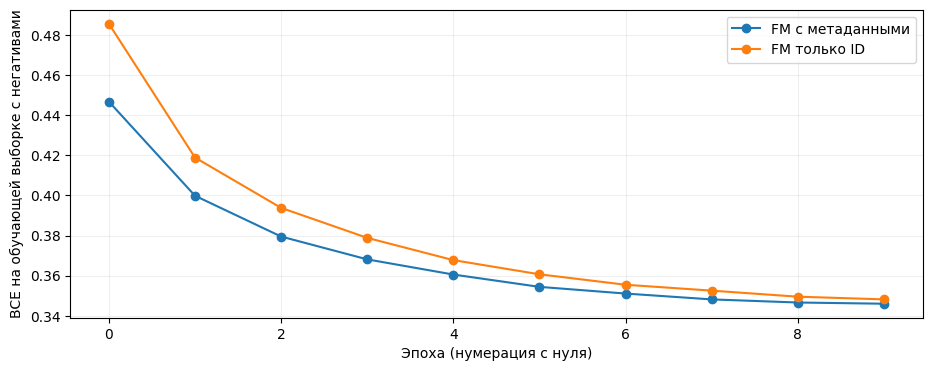

In [14]:
# Контрольная FM: гиперпараметры уже выбраны; test по-прежнему не используется.
id_uf, id_itf, _ = make_features(protocol['train'], *counts.shape, metadata=False)
fm_without_metadata = FM(**selected['FM']).fit(counts, id_uf, id_itf)
ablation_val, _ = evaluate(fm_without_metadata, protocol['validation'], protocol['seen_validation'])
print('ID-only FM validation:', ablation_val)
plt.plot(models['FM'].loss_history, marker='o', label='FM с метаданными')
plt.plot(fm_without_metadata.loss_history, marker='o', label='FM только ID')
plt.xlabel('Эпоха (нумерация с нуля)'); plt.ylabel('BCE на обучающей выборке с негативами'); plt.legend(); plt.show()


## 5. Финальный test
Настройки зафиксированы выше; один финальный проход по test для каждой выбранной модели и заранее
заданной ablation. Не меняем параметры по этим результатам. Общая таблица включает гиперпараметры.
Доверительные интервалы парного bootstrap по пользователям оценивают вариативность данной когорты,
но не учитывают другие seed обучения или будущие временные окна.

,model,NDCG@10,Recall@10,Precision@10,Coverage@10,users,params
0,EASE,0.077672,0.054635,0.062571,0.280697,1229,"{""reg"": 300.0}"
1,RepeatTargetIALS,0.064520,0.047180,0.051505,0.324380,1229,"{""alpha"": 20.0, ""beta"": 0.75, ""factors"": 64, ""iterations"": 12, ""reg"": 10.0, ""seed"": 42}"
2,IALS,0.063868,0.046719,0.051017,0.342090,1229,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""reg"": 10.0, ""seed"": 42}"
3,ItemKNN,0.058309,0.040027,0.046949,0.252066,1229,"{""neighbors"": 50, ""shrink"": 0}"
4,FM_ID_only (ablation),0.056277,0.034950,0.047437,0.173849,1229,"{""epochs"": 10, ""factors"": 16, ""lr"": 0.01, ""negatives"": 3, ""reg"": 1e-05, ""seed"": 42}"
5,FM,0.054906,0.035045,0.046786,0.169126,1229,"{""epochs"": 10, ""factors"": 16, ""lr"": 0.01, ""negatives"": 3, ""reg"": 1e-05, ""seed"": 42}"


,comparison,delta,low,high
0,Repeat target − binary target,0.000652,-0.003974,0.004923
1,FM metadata − FM IDs,-0.001371,-0.006024,0.003077


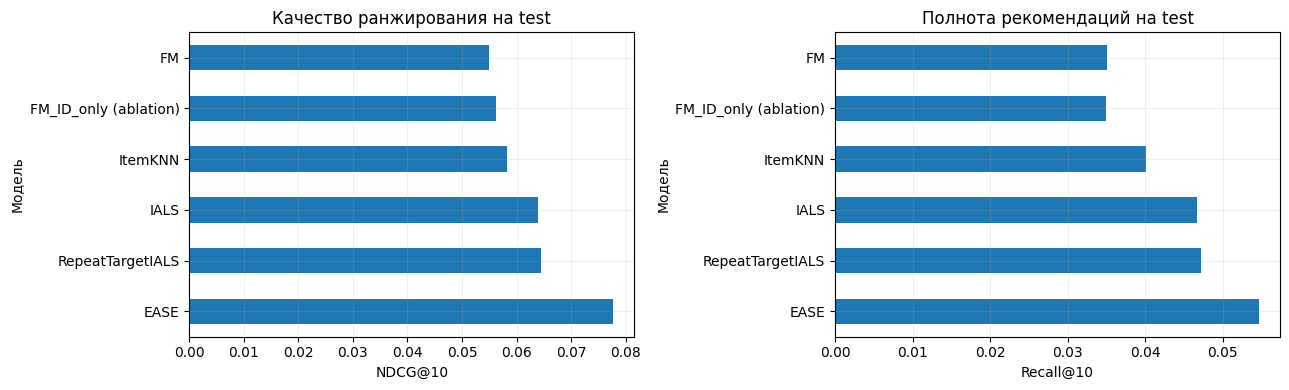

In [15]:
test_rows, per_user = [], {}
for name, model in {**models, 'FM_ID_only (ablation)': fm_without_metadata}.items():
    metrics, details = evaluate(model, protocol['test'], protocol['seen_test'])
    per_user[name] = details
    params = selected['FM'] if name.startswith('FM_ID') else selected[name]
    test_rows.append({'model': name, **metrics, 'params': json.dumps(params, sort_keys=True)})
test_results = pd.DataFrame(test_rows).sort_values('NDCG@10', ascending=False).reset_index(drop=True)
display(test_results)
test_results.to_csv('results/test.csv', index=False)
comparison = pd.DataFrame([
    {'comparison': 'Repeat target − binary target', **paired_bootstrap(per_user['RepeatTargetIALS'], per_user['IALS'])},
    {'comparison': 'FM metadata − FM IDs', **paired_bootstrap(per_user['FM'], per_user['FM_ID_only (ablation)'])}
])
display(comparison)
comparison.to_csv('results/paired_bootstrap.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
test_results.plot.barh(x='model', y='NDCG@10', legend=False, ax=axes[0])
test_results.plot.barh(x='model', y='Recall@10', legend=False, ax=axes[1])
axes[0].set(title='Качество ранжирования на test', xlabel='NDCG@10', ylabel='Модель')
axes[1].set(title='Полнота рекомендаций на test', xlabel='Recall@10', ylabel='Модель')
plt.tight_layout(); plt.show()


### Пример персональной выдачи
Покупатель выбирается детерминированно: первый ID в test-когорте. Показываем рекомендации победителя
среди пяти основных методов и совпадения с будущими новыми покупками. Пример иллюстрирует выдачу,
но не заменяет агрегированные метрики.

In [16]:
main_results = test_results[~test_results.model.str.contains('ablation')]
winner = main_results.iloc[0]['model']
u = min(protocol['test'])
rec = recommend(models[winner], [u], protocol['seen_test'])[0]
titles = protocol['train'].groupby('i').Description.last()
display(pd.DataFrame({'rank': np.arange(1, 11), 'StockCode': protocol['items'][rec],
                      'title': titles.reindex(rec).to_numpy(),
                      'relevant': np.isin(rec, protocol['test'][u])}))
print('CustomerID:', protocol['users'][u], '| model:', winner)


,rank,StockCode,title,relevant
0,1,21212,PACK OF 72 RETROSPOT CAKE CASES,False
1,2,21977,PACK OF 60 PINK PAISLEY CAKE CASES,False
2,3,22730,ALARM CLOCK BAKELIKE IVORY,False
3,4,23245,SET OF 3 REGENCY CAKE TINS,False
4,5,22951,60 CAKE CASES DOLLY GIRL DESIGN,False
5,6,21213,PACK OF 72 SKULL CAKE CASES,False
6,7,23148,MINIATURE ANTIQUE ROSE HOOK IVORY,False
7,8,84997A,CHILDRENS CUTLERY POLKADOT GREEN,False
8,9,84378,SET OF 3 HEART COOKIE CUTTERS,False
9,10,23307,SET OF 60 PANTRY DESIGN CAKE CASES,False


CustomerID: 12347 | model: EASE


## 6. Выводы по полученным результатам
Сопоставим качество методов, выбранные настройки и результаты двух контрольных сравнений.

In [17]:
indexed = test_results.set_index('model')
best = indexed.loc[winner]
lines = [f"**Лучший из пяти основных методов: {winner}.** NDCG@10 = {best['NDCG@10']:.4f}, "
         f"Recall@10 = {best['Recall@10']:.4f}. Настройки: `{selected[winner]}`."]
for row in comparison.itertuples():
    direction = 'положительное' if row.delta > 0 else 'отрицательное'
    uncertainty = ('Интервал включает ноль: устойчивый эффект на этой когорте не подтверждён.'
                   if row.low <= 0 <= row.high else 'Интервал не включает ноль на этой когорте.')
    lines.append(f"**{row.comparison}:** изменение NDCG@10 {row.delta:+.4f}, "
                 f"95% парный bootstrap [{row.low:+.4f}, {row.high:+.4f}]; направление {direction}. {uncertainty}")
lines.append('Лучший метод на validation: **' + validation_results.loc[validation_results['NDCG@10'].idxmax(), 'model'] + '**. '
             'Результаты test используются только для отчёта; повторного выбора настроек нет.')

runner_up = main_results.iloc[1]
lines.append(f"Отрыв от второго метода ({runner_up['model']}) по NDCG@10 составляет "
             f"{best['NDCG@10'] - runner_up['NDCG@10']:.4f}. Это наблюдаемая разница на одном временном окне, "
             "а не утверждение об универсальном превосходстве метода.")
lines.append(f"Выбранная полная FM: `{selected['FM']}`. "
             f"Её train BCE снизилась с {models['FM'].loss_history[0]:.3f} до {models['FM'].loss_history[-1]:.3f}. "
             "Снижение обучающей ошибки не гарантирует улучшение top-10: оптимизируется BCE с выбранными негативами, "
             "а оценивается ранжирование полного каталога. Для вывода о пользе признаков важна именно ablation на test.")
display(Markdown('\n\n'.join(lines)))
elapsed = time.perf_counter() - started
environment = {'python': platform.python_version(), 'platform': platform.platform(),
               'numpy': np.__version__, 'seed': SEED, 'blas_threads': 1, 'elapsed_seconds': elapsed,
               'dataset_sha256': sha256, 'train_end': str(TRAIN_END), 'validation_end': str(VALID_END)}
Path('results/run_info.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print(f'Полное выполнение: {elapsed / 60:.1f} мин.')


**Лучший из пяти основных методов: EASE.** NDCG@10 = 0.0777, Recall@10 = 0.0546. Настройки: `{'reg': 300.0}`.

**Repeat target − binary target:** изменение NDCG@10 +0.0007, 95% парный bootstrap [-0.0040, +0.0049]; направление положительное. Интервал включает ноль: устойчивый эффект на этой когорте не подтверждён.

**FM metadata − FM IDs:** изменение NDCG@10 -0.0014, 95% парный bootstrap [-0.0060, +0.0031]; направление отрицательное. Интервал включает ноль: устойчивый эффект на этой когорте не подтверждён.

Лучший метод на validation: **EASE**. Результаты test используются только для отчёта; повторного выбора настроек нет.

Отрыв от второго метода (RepeatTargetIALS) по NDCG@10 составляет 0.0132. Это наблюдаемая разница на одном временном окне, а не утверждение об универсальном превосходстве метода.

Выбранная полная FM: `{'factors': 16, 'reg': 1e-05, 'epochs': 10, 'lr': 0.01, 'negatives': 3, 'seed': 42}`. Её train BCE снизилась с 0.447 до 0.346. Снижение обучающей ошибки не гарантирует улучшение top-10: оптимизируется BCE с выбранными негативами, а оценивается ранжирование полного каталога. Для вывода о пользе признаков важна именно ablation на test.

Полное выполнение: 1.3 мин.


### Интерпретация и ограничения
- Эффект custom-таргета из таблицы — изолированное сравнение с iALS при одинаковых confidence и настройках.
  Небольшое улучшение при выбранном beta не подтверждено доверительным интервалом.
  Повторяемость известных покупок не обязательно переносится на поиск новых товаров.
- FM ablation измеряет совокупный эффект страны, слов названия и ценовой группы при фиксированных
  настройках полной FM. Она не выделяет вклад каждого признака; ID-only вариант отдельно не подбирался.
- Покупка наблюдается только после экспозиции; неизвестные пары не гарантированно нерелевантны.
  Данные не содержат логов показов, остатков и настоящего каталога на дату выдачи.
  В train-каталоге могут быть уже недоступные к test товары. Цена — исторический сегмент, не актуальная цена.
- Удаление отмен не связывает их с исходными покупками: положительная покупка может позже быть возвращена.
  Значит, релевантность означает факт положительной покупки, а не удовлетворённость товаром.
- Оптовики, неодинаковые горизонты validation/test и сезонность подарков ограничивают переносимость выводов.
  Модели заморожены на два месяца до test; нет cold-start оценки, онлайн-эксперимента и проверки на других seed.
- Когорта с новыми покупками исключает неактивных пользователей и тех, кто покупал только известные товары.
  Метрики нельзя интерпретировать как конверсию всей аудитории.
- EASE требует $O(I^2)$ памяти и $O(I^3)$ времени решения; здесь каталог небольшой.
  Сетка ограничена вычислительным бюджетом. Для более сильного вывода нужны несколько временных окон,
  больше seed и отдельные ablation признаков, без повторного подбора по этому test.